In [6]:
from pathlib import Path
import sys

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in [start, *start.parents]:
        if (path / "src").is_dir() and (path / "notebooks").is_dir():
            return path
    raise RuntimeError("Could not find project root containing src/ and notebooks/")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\study\Code\python-studies\nanoparticle-diffusion-104337


In [7]:
import numpy as np
import matplotlib.pyplot as plt

In [8]:
k_B = 1.380649e-23

temperature = 310

viscosity = 0.001

radius = 50e-9

D = (k_B * temperature) / (6 * np.pi * viscosity * radius)

dt = 0.01

step_size = np.sqrt(2 * D * dt)

In [9]:
particles = 100

steps = 1000

x = np.zeros((particles, steps))
y = np.zeros((particles, steps))

np.random.seed(42)

for p in range(particles):

    for i in range(1, steps):

        x[p, i] = x[p, i-1] + np.random.normal(0, step_size)
        y[p, i] = y[p, i-1] + np.random.normal(0, step_size)

In [10]:
from src.analysis import calculate_msd
lag_times, msd = calculate_msd(x, y)
time = lag_times * dt

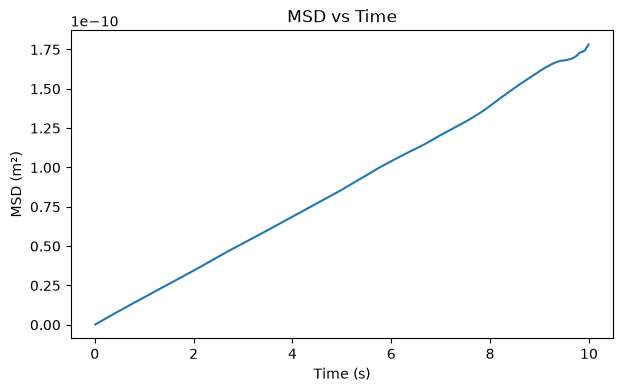

In [11]:
plt.figure(figsize=(7,4))
plt.plot(time, msd)
plt.xlabel("Time (s)")
plt.ylabel("MSD (m²)")
plt.title("MSD vs Time")
plt.show()

In [12]:
slope, intercept = np.polyfit(time, msd, 1)

D_estimated = slope / 4

print("Theoretical D :", D)
print("Estimated D   :", D_estimated)

Theoretical D : 4.541233669180899e-12
Estimated D   : 4.412208974140844e-12
